# Fourier Transform of the Triangular (Hat) Function

This exercise derives the Fourier transform of the triangular hat function $f(x)$, defined as:

$$f(x) = \begin{cases} 1 + x & -1 < x < 0 \\ 1 - x & 0 \leq x \leq 1 \\ 0 & |x| \geq 1 \end{cases}$$

Using the Fourier transform convention:
$$\hat{f}(\omega) = \int_{-\infty}^{\infty} f(x)\, e^{i\omega x}\, dx$$

The integral is split into two parts over $[-1, 0]$ and $[0, 1]$, and each is evaluated via **integration by parts**. The final result is:

$$\hat{f}(\omega) = \frac{2(1 - \cos\omega)}{\omega^2}$$

The whiteboard below shows the full hand-worked derivation.

Note* you could as well use the kernel - $$e^{-i\omega x}$$

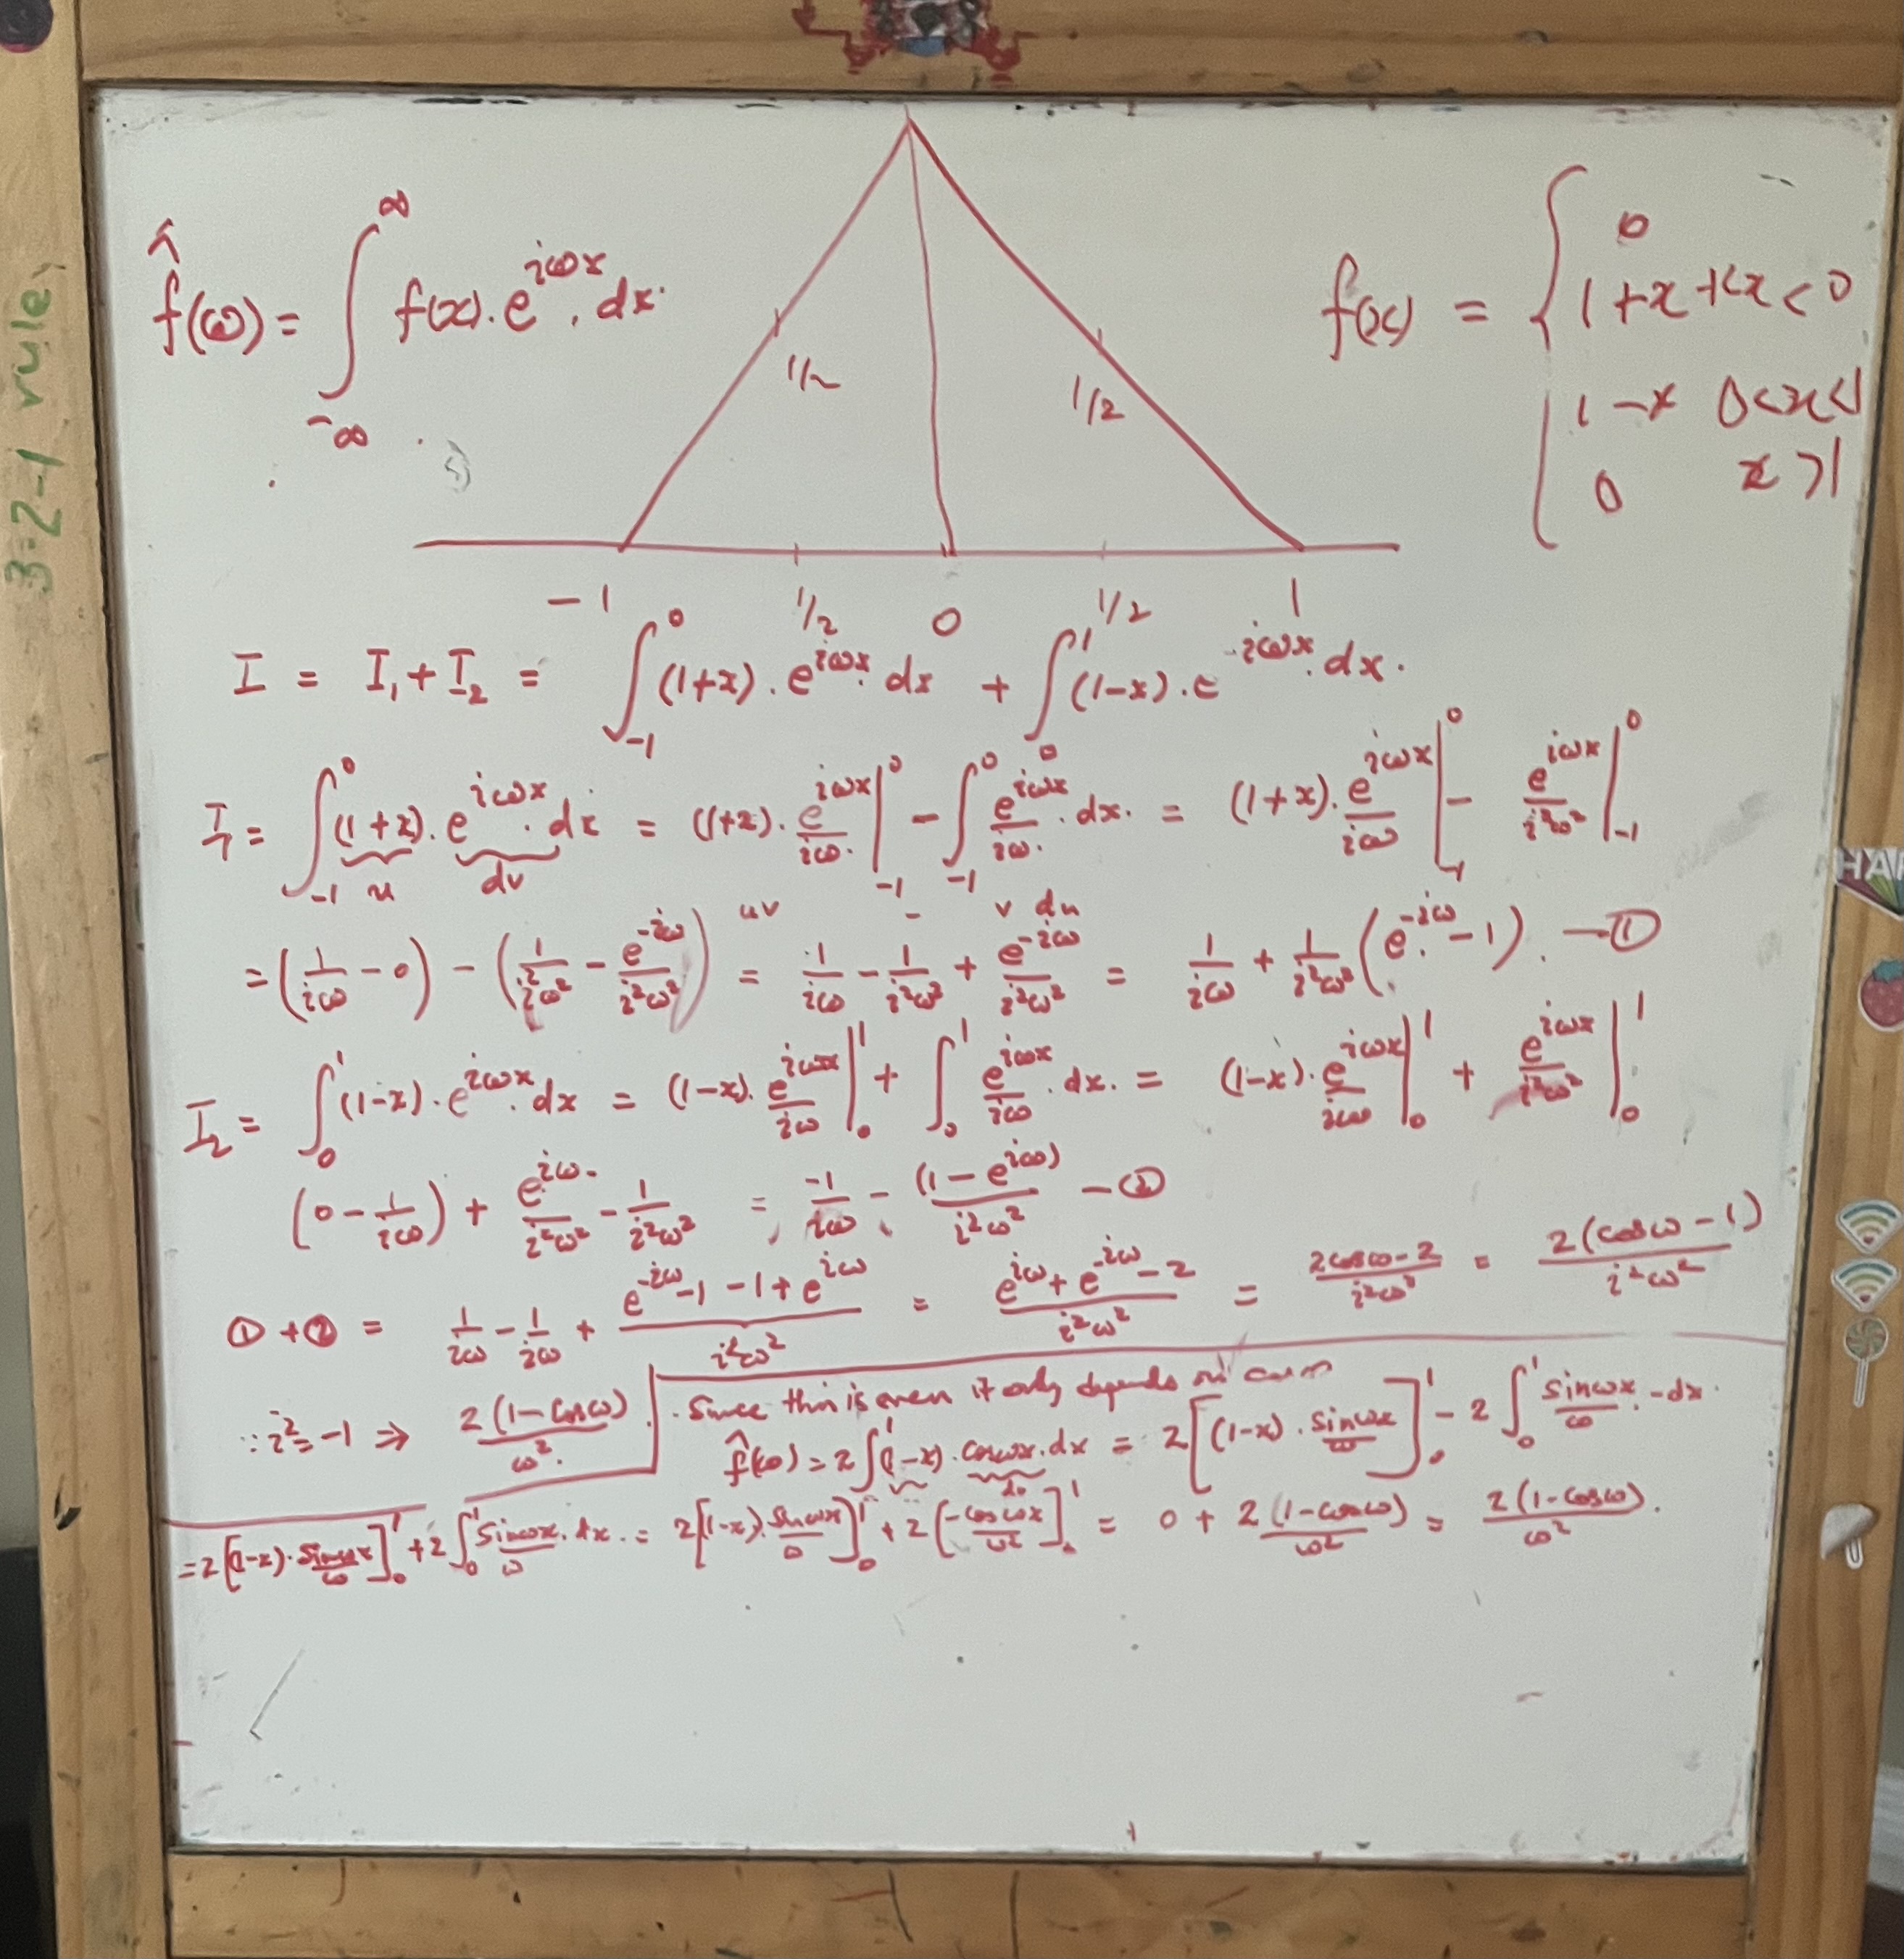

In [7]:
from IPython.display import Image, display

display(Image(filename='../DATA/chapter_ex2_triangular_wave.jpeg'))


In [8]:
import numpy as np
from scipy import integrate

def f(x):
    """Triangular hat function."""
    return np.where(x < 0, 1 + x, 1 - x) * (np.abs(x) < 1)

def ft_numerical(omega):
    """Numerical Fourier transform via quadrature."""
    real_part, _ = integrate.quad(lambda x: f(x) * np.cos(omega * x), -1, 1)
    imag_part, _ = integrate.quad(lambda x: f(x) * np.sin(omega * x), -1, 1)
    return complex(real_part, imag_part)

def ft_analytic(omega):
    """Closed-form result: 2(1 - cos(omega)) / omega^2."""
    if np.isclose(omega, 0):
        return 1.0  # limit as omega -> 0
    return 2 * (1 - np.cos(omega)) / omega**2

# Compare at several frequencies
test_omegas = [0.5, 1.0, 2.0, np.pi, 5.0, 10.0]
print(f"{'omega':>8}  {'Numerical (Re)':>16}  {'Analytic':>16}  {'Match':>8}")
print("-" * 58)
for omega in test_omegas:
    num = ft_numerical(omega).real
    ana = ft_analytic(omega)
    print(f"{omega:>8.3f}  {num:>16.8f}  {ana:>16.8f}  {str(np.isclose(num, ana)):>8}")


   omega    Numerical (Re)          Analytic     Match
----------------------------------------------------------
   0.500        0.97933950        0.97933950      True
   1.000        0.91939539        0.91939539      True
   2.000        0.70807342        0.70807342      True
   3.142        0.40528473        0.40528473      True
   5.000        0.05730703        0.05730703      True
  10.000        0.03678143        0.03678143      True


## Removable Singularity at $\omega = 0$

The denominator $\omega^2$ might suggest a singularity at $\omega = 0$, but this is actually a **removable singularity** — the function is perfectly well-behaved there.

Using the Taylor expansion of cosine:

$$\cos\omega = 1 - \frac{\omega^2}{2} + \frac{\omega^4}{24} - \cdots$$

The numerator becomes:

$$1 - \cos\omega = \frac{\omega^2}{2} - \frac{\omega^4}{24} + \cdots$$

So the expression simplifies to:

$$\frac{2(1-\cos\omega)}{\omega^2} = \frac{2\!\left(\dfrac{\omega^2}{2} - \dfrac{\omega^4}{24} + \cdots\right)}{\omega^2} = 1 - \frac{\omega^2}{12} + \cdots$$

Taking the limit:

$$\lim_{\omega \to 0} \frac{2(1-\cos\omega)}{\omega^2} = 1$$

The $\omega^2$ in the numerator (from $1 - \cos\omega$) exactly cancels the $\omega^2$ in the denominator — no singularity.

This also makes physical sense: $\hat{f}(0) = \int_{-1}^{1} f(x)\,dx$ is simply the **area under the triangular hat** — a triangle with base 2 and height 1 — which equals $\mathbf{1}$. $\checkmark$

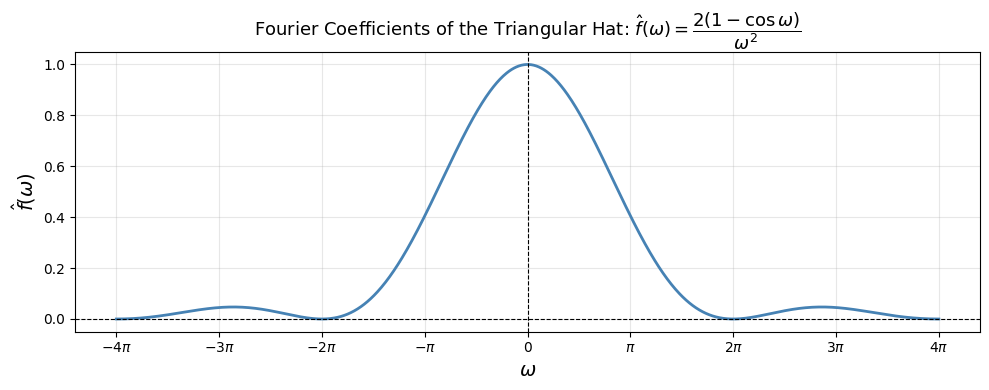

In [9]:
import matplotlib.pyplot as plt

omega = np.linspace(-4 * np.pi, 4 * np.pi, 1000)

# Analytic coefficients with removable singularity handled
coeffs = np.where(
    np.isclose(omega, 0),
    1.0,
    2 * (1 - np.cos(omega)) / omega**2
)

plt.figure(figsize=(10, 4))
plt.plot(omega, coeffs, color='steelblue', linewidth=2)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.xlabel(r'$\omega$', fontsize=14)
plt.ylabel(r'$\hat{f}(\omega)$', fontsize=14)
plt.title(r'Fourier Coefficients of the Triangular Hat: $\hat{f}(\omega) = \dfrac{2(1-\cos\omega)}{\omega^2}$', fontsize=13)
plt.xticks(
    [-4*np.pi, -3*np.pi, -2*np.pi, -np.pi, 0, np.pi, 2*np.pi, 3*np.pi, 4*np.pi],
    [r'$-4\pi$', r'$-3\pi$', r'$-2\pi$', r'$-\pi$', r'$0$', r'$\pi$', r'$2\pi$', r'$3\pi$', r'$4\pi$']
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:
import ipywidgets as widgets

x_plot = np.linspace(-1, 1, 1000)

# Periodic triangular wave (period = 2), the periodic extension of the hat function
f_true = 1 - np.abs(((x_plot + 1) % 2) - 1)

def reconstruct(x, N):
    """Reconstruct using first N Fourier modes of the periodic triangular hat (period=2).
    Fourier series: a0/2 + sum_n a_n * cos(n*pi*x),  a_n = 2(1-cos(n*pi))/(n^2*pi^2)
    Only odd n contribute (even n give a_n = 0).
    """
    result = np.full_like(x, 0.5, dtype=float)  # a_0 / 2
    for n in range(1, N + 1):
        a_n = 2 * (1 - np.cos(n * np.pi)) / (n**2 * np.pi**2)
        result += a_n * np.cos(n * np.pi * x)
    return result

def plot_reconstruction(N):
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(x_plot, f_true, color='orange', linewidth=1.5,
            linestyle='--', label='True triangular wave', zorder=2)
    ax.plot(x_plot, reconstruct(x_plot, N), color='steelblue', linewidth=2,
            label=f'Fourier reconstruction  (N = {N})', zorder=3)
    ax.set_xlabel(r'$x$', fontsize=13)
    ax.set_ylabel(r'$f(x)$', fontsize=13)
    ax.set_title(
        f'Triangular Wave Reconstruction — first N={N} Fourier modes\n'
        r'$f(x) \approx \frac{1}{2} + \sum_{n=1}^{N} \frac{2(1-\cos n\pi)}{n^2\pi^2}\cos(n\pi x)$',
        fontsize=12)
    ax.legend(fontsize=11)
    ax.set_ylim(-0.25, 1.35)
    ax.set_xlim(x_plot[0], x_plot[-1])
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

slider = widgets.IntSlider(
    value=1, min=1, max=40, step=1,
    description='N modes:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='520px')
)
widgets.interact(plot_reconstruction, N=slider)


interactive(children=(IntSlider(value=1, description='N modes:', layout=Layout(width='520px'), max=40, min=1, …

<function __main__.plot_reconstruction(N)>